# Meal Memory: Image Model Calibration and Evaluation

Freeze the model selected using validation loss. Use the calibration
partition to choose a review threshold, then evaluate the fixed system
on held-out test data.

AI attribution: Initial code and explanations drafted with assistance
from OpenAI ChatGPT.

In [1]:
# AI attribution: Drafted with assistance from OpenAI ChatGPT.
from pathlib import Path
import json

import numpy as np
import pandas as pd
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from torchvision.models import (
    efficientnet_b0,
    EfficientNet_B0_Weights,
)
from PIL import Image

PROJECT_ROOT = Path("/home/users/al581/meal-memory")
IMAGE_ROOT = PROJECT_ROOT / "data" / "raw" / "food-101"
RESULTS_DIR = PROJECT_ROOT / "docs" / "results"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

manifest = pd.read_csv(
    PROJECT_ROOT / "data" / "splits" / "food20_manifest.csv"
)

with (
    PROJECT_ROOT / "data" / "splits" / "food20_config.json"
).open() as file:
    food_config = json.load(file)

classes = food_config["classes"]
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

checkpoint_path = (
    PROJECT_ROOT / "checkpoints"
    / "efficientnet_augmented_v1" / "best.pt"
)
checkpoint = torch.load(
    checkpoint_path,
    map_location="cpu",
    weights_only=True,
)

assert checkpoint["classes"] == classes
assert checkpoint["class_to_idx"] == food_config["class_to_idx"]

model = efficientnet_b0(weights=None)
model.classifier[1] = nn.Linear(
    model.classifier[1].in_features, len(classes)
)
model.load_state_dict(checkpoint["model_state_dict"])
model = model.to(device).eval()

preprocess = EfficientNet_B0_Weights.DEFAULT.transforms()


class EvaluationDataset(Dataset):
    """Load a fixed evaluation partition.

    AI attribution: Drafted with assistance from OpenAI ChatGPT.
    """

    def __init__(self, rows):
        self.rows = rows.reset_index(drop=True).copy()

    def __len__(self):
        return len(self.rows)

    def __getitem__(self, index):
        row = self.rows.iloc[index]
        with Image.open(IMAGE_ROOT / row["relative_path"]) as image:
            image = preprocess(image.convert("RGB"))
        return image, int(row["label"])


calibration_rows = manifest[
    manifest["split"] == "calibration"
].reset_index(drop=True)

assert len(calibration_rows) == 1500

calibration_loader = DataLoader(
    EvaluationDataset(calibration_rows),
    batch_size=32,
    shuffle=False,
    num_workers=0,
    pin_memory=(device.type == "cuda"),
)

probability_batches = []
label_batches = []

with torch.inference_mode():
    for images, labels in calibration_loader:
        logits = model(images.to(device))
        probability_batches.append(logits.softmax(dim=1).cpu())
        label_batches.append(labels)

calibration_probabilities = torch.cat(
    probability_batches
).numpy()
calibration_labels = torch.cat(label_batches).numpy()

assert np.isfinite(calibration_probabilities).all()

print("Selected checkpoint epoch:", checkpoint["epoch"])
print("Device:", device)
print("Calibration probabilities:", calibration_probabilities.shape)
print(
    "Calibration accuracy:",
    f"{(calibration_probabilities.argmax(axis=1) == calibration_labels).mean():.1%}",
)

Selected checkpoint epoch: 5
Device: cuda
Calibration probabilities: (1500, 20)
Calibration accuracy: 82.3%


In [2]:
# AI attribution: Drafted with assistance from OpenAI ChatGPT.
confidence = calibration_probabilities.max(axis=1)
predictions = calibration_probabilities.argmax(axis=1)
correct = predictions == calibration_labels

TARGET_ACCURACY = 0.90
MIN_ACCEPTED = 100

# Evaluate every distinct confidence threshold.
# Equal-confidence predictions are always accepted/rejected together.
order = np.argsort(-confidence, kind="stable")
sorted_confidence = confidence[order]
cumulative_correct = np.cumsum(correct[order])

group_ends = np.flatnonzero(
    np.r_[sorted_confidence[:-1] != sorted_confidence[1:], True]
)
accepted_counts = group_ends + 1

threshold_results = pd.DataFrame({
    "threshold": sorted_confidence[group_ends],
    "accepted": accepted_counts,
    "coverage": accepted_counts / len(confidence),
    "accepted_accuracy": (
        cumulative_correct[group_ends] / accepted_counts
    ),
})

eligible = threshold_results[
    (threshold_results["accepted_accuracy"] >= TARGET_ACCURACY)
    & (threshold_results["accepted"] >= MIN_ACCEPTED)
]

threshold_results.to_csv(
    RESULTS_DIR / "calibration_threshold_curve.csv",
    index=False,
)

if eligible.empty:
    raise RuntimeError(
        "No threshold reached 90% calibration accuracy with at "
        "least 100 accepted images. Stop here to review the results."
    )

# Maximum coverage among thresholds meeting the target.
selected = eligible.loc[eligible["accepted"].idxmax()]
SELECTED_THRESHOLD = float(selected["threshold"])

print(f"Selected threshold: {SELECTED_THRESHOLD:.6f}")
print(
    f"Accepted: {int(selected['accepted'])}"
    f"/{len(confidence)}"
)
print(f"Coverage: {selected['coverage']:.1%}")
print(
    "Accuracy among accepted predictions:",
    f"{selected['accepted_accuracy']:.1%}",
)
print(
    "Sent for review:",
    f"{1 - selected['coverage']:.1%}",
)

threshold_config = {
    "checkpoint": str(checkpoint_path.relative_to(PROJECT_ROOT)),
    "checkpoint_epoch": int(checkpoint["epoch"]),
    "classes": classes,
    "confidence_definition": "maximum softmax probability",
    "acceptance_rule": "confidence >= threshold",
    "threshold": SELECTED_THRESHOLD,
    "target_calibration_accuracy": TARGET_ACCURACY,
    "minimum_accepted_calibration_images": MIN_ACCEPTED,
    "calibration_images": len(confidence),
    "accepted_calibration_images": int(selected["accepted"]),
    "calibration_coverage": float(selected["coverage"]),
    "calibration_accepted_accuracy": float(
        selected["accepted_accuracy"]
    ),
}

with (RESULTS_DIR / "review_threshold.json").open("w") as file:
    json.dump(threshold_config, file, indent=2)

Selected threshold: 0.583667
Accepted: 1276/1500
Coverage: 85.1%
Accuracy among accepted predictions: 90.0%
Sent for review: 14.9%


In [3]:
# AI attribution: Drafted with assistance from OpenAI ChatGPT.
from sklearn.metrics import accuracy_score, f1_score, log_loss

with (RESULTS_DIR / "review_threshold.json").open() as file:
    locked_config = json.load(file)

assert locked_config["checkpoint"] == str(
    checkpoint_path.relative_to(PROJECT_ROOT)
)
assert locked_config["classes"] == classes

locked_threshold = locked_config["threshold"]

test_rows = manifest[
    manifest["split"] == "test"
].reset_index(drop=True)

assert len(test_rows) == 5000
assert set(test_rows["image_id"]).isdisjoint(
    calibration_rows["image_id"]
)

test_loader = DataLoader(
    EvaluationDataset(test_rows),
    batch_size=32,
    shuffle=False,
    num_workers=0,
    pin_memory=(device.type == "cuda"),
)

test_probability_batches = []
test_label_batches = []

model.eval()
with torch.inference_mode():
    for images, labels in test_loader:
        logits = model(images.to(device))
        test_probability_batches.append(
            logits.softmax(dim=1).cpu()
        )
        test_label_batches.append(labels)

test_probabilities = torch.cat(test_probability_batches).numpy()
test_labels = torch.cat(test_label_batches).numpy()

assert np.isfinite(test_probabilities).all()
assert len(test_probabilities) == len(test_rows)

test_predictions = test_probabilities.argmax(axis=1)
test_confidence = test_probabilities.max(axis=1)
test_correct = test_predictions == test_labels
accepted = test_confidence >= locked_threshold

top_three = np.argsort(
    -test_probabilities, axis=1, kind="stable"
)[:, :3]
top_three_accuracy = (
    top_three == test_labels[:, None]
).any(axis=1).mean()

test_metrics = {
    "test_images": len(test_labels),
    "top1_accuracy": float(
        accuracy_score(test_labels, test_predictions)
    ),
    "top3_accuracy": float(top_three_accuracy),
    "macro_f1": float(
        f1_score(
            test_labels,
            test_predictions,
            labels=list(range(len(classes))),
            average="macro",
            zero_division=0,
        )
    ),
    "cross_entropy": float(
        log_loss(
            test_labels,
            test_probabilities,
            labels=list(range(len(classes))),
        )
    ),
    "threshold": locked_threshold,
    "accepted_images": int(accepted.sum()),
    "review_images": int((~accepted).sum()),
    "coverage": float(accepted.mean()),
    "accepted_accuracy": (
        float(test_correct[accepted].mean())
        if accepted.any() else None
    ),
    "review_group_accuracy": (
        float(test_correct[~accepted].mean())
        if (~accepted).any() else None
    ),
}

with (RESULTS_DIR / "image_test_metrics.json").open("w") as file:
    json.dump(test_metrics, file, indent=2)

test_details = test_rows[
    ["image_id", "class_name", "label"]
].copy()
test_details["predicted_class"] = [
    classes[index] for index in test_predictions
]
test_details["confidence"] = test_confidence
test_details["correct"] = test_correct
test_details["accepted"] = accepted

test_details.to_csv(
    RESULTS_DIR / "image_test_predictions.csv",
    index=False,
)

print(f"Test images: {len(test_labels):,}")
print(f"Top-1 accuracy: {test_metrics['top1_accuracy']:.1%}")
print(f"Top-3 accuracy: {test_metrics['top3_accuracy']:.1%}")
print(f"Macro-F1: {test_metrics['macro_f1']:.4f}")
print(f"Cross-entropy: {test_metrics['cross_entropy']:.4f}")
print(f"\nAccepted: {accepted.sum():,}/{len(test_labels):,}")
print(f"Coverage: {test_metrics['coverage']:.1%}")

if accepted.any():
    print(
        "Accuracy among accepted predictions:",
        f"{test_metrics['accepted_accuracy']:.1%}",
    )

print(f"Sent for review: {(~accepted).sum():,}")
print("\nSaved test metrics and per-image predictions.")

Test images: 5,000
Top-1 accuracy: 86.5%
Top-3 accuracy: 97.1%
Macro-F1: 0.8649
Cross-entropy: 0.4369

Accepted: 4,371/5,000
Coverage: 87.4%
Accuracy among accepted predictions: 92.3%
Sent for review: 629

Saved test metrics and per-image predictions.


Five categories with lowest F1:


,precision,recall,f1-score,support
class_name,,,,
apple_pie,0.805430,0.712,0.755839,250.0
omelette,0.794239,0.772,0.782961,250.0
french_toast,0.803347,0.768,0.785276,250.0
pancakes,0.733333,0.880,0.800000,250.0
risotto,0.757042,0.860,0.805243,250.0


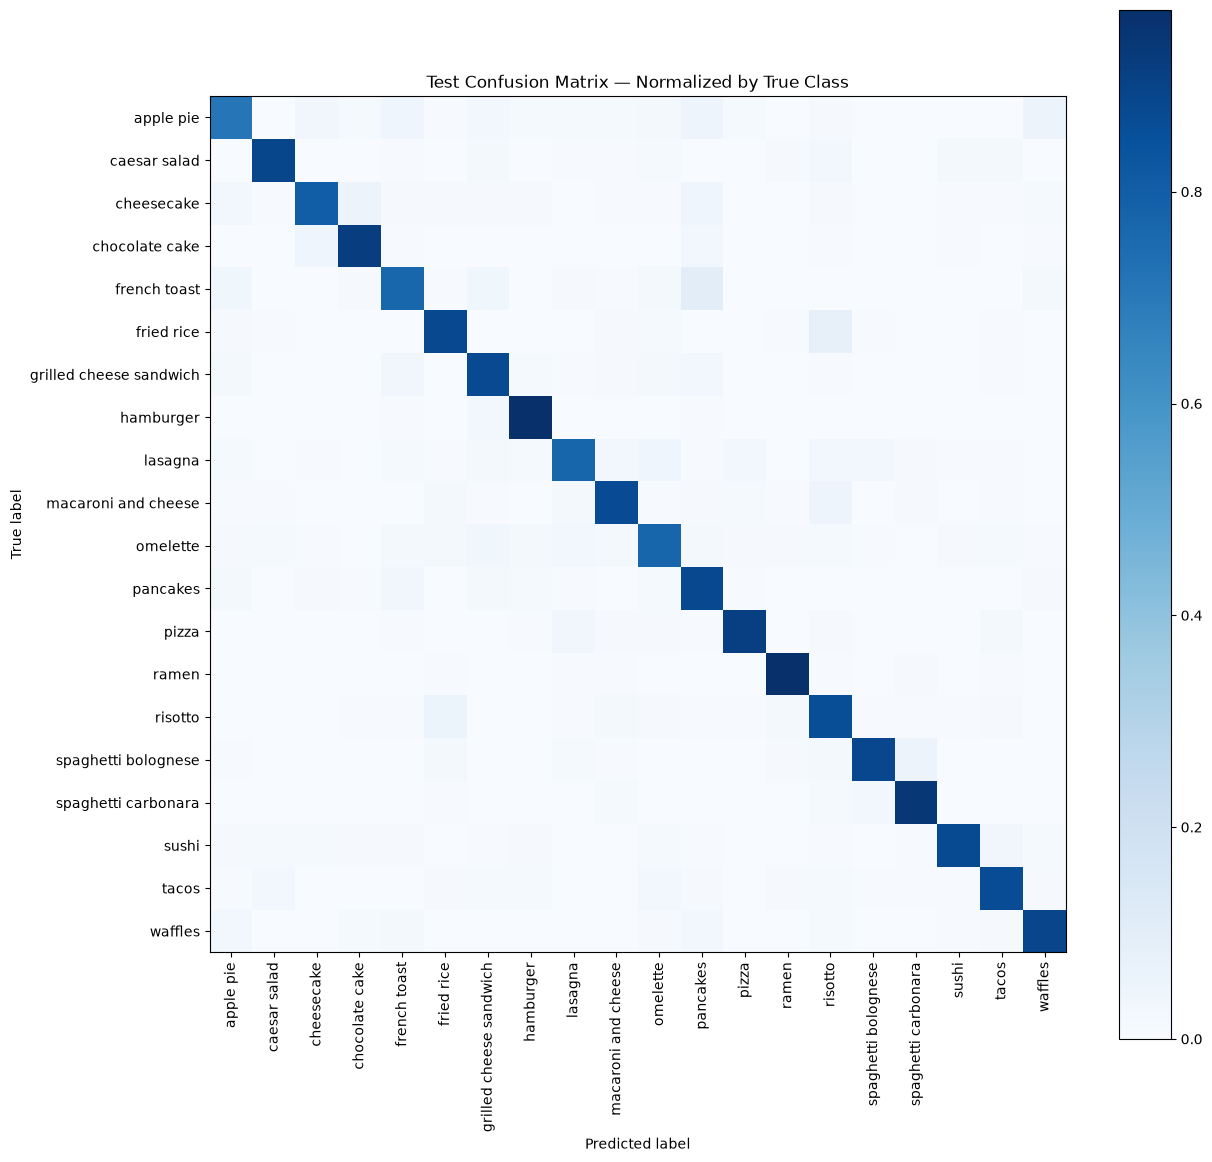

In [4]:
# AI attribution: Drafted with assistance from OpenAI ChatGPT.
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

report = classification_report(
    test_labels,
    test_predictions,
    labels=list(range(len(classes))),
    target_names=classes,
    output_dict=True,
    zero_division=0,
)

per_class_results = pd.DataFrame({
    name: report[name] for name in classes
}).T

per_class_results.index.name = "class_name"
per_class_results.to_csv(
    RESULTS_DIR / "image_test_per_class.csv"
)

print("Five categories with lowest F1:")
display(per_class_results.sort_values("f1-score").head(5))

fig, ax = plt.subplots(figsize=(13, 12))

ConfusionMatrixDisplay.from_predictions(
    test_labels,
    test_predictions,
    labels=list(range(len(classes))),
    display_labels=[
        name.replace("_", " ") for name in classes
    ],
    normalize="true",
    include_values=False,
    cmap="Blues",
    xticks_rotation=90,
    ax=ax,
)

ax.set_title("Test Confusion Matrix — Normalized by True Class")
plt.tight_layout()
plt.savefig(
    RESULTS_DIR / "image_test_confusion_matrix.png",
    dpi=150,
    bbox_inches="tight",
)
plt.show()

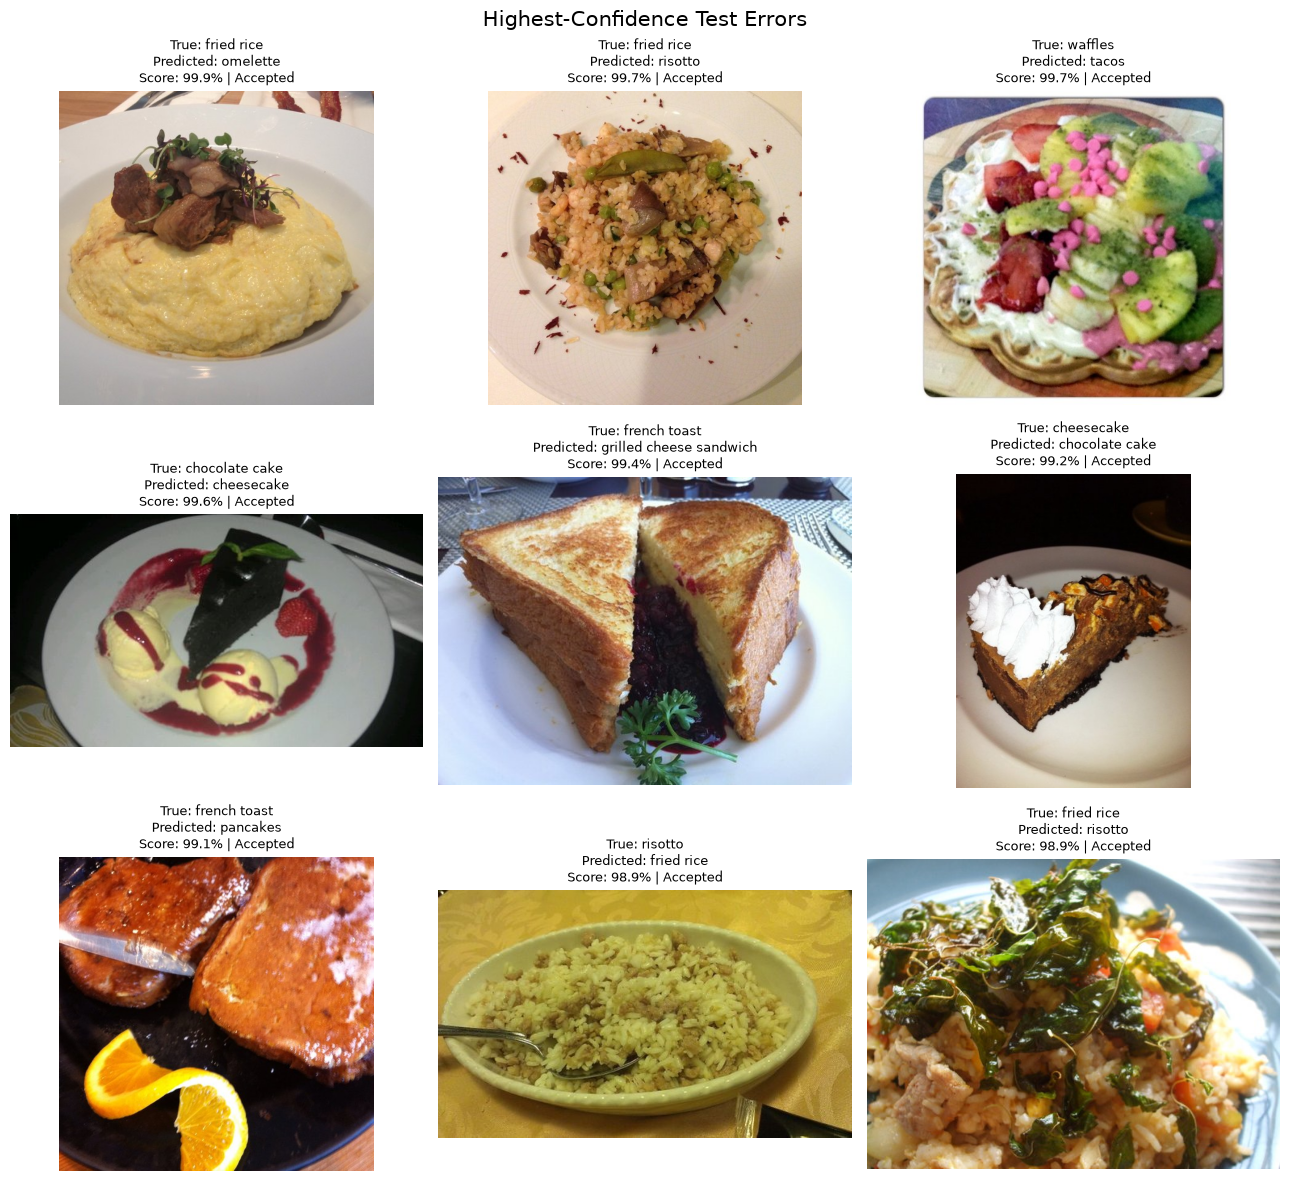

In [5]:
# AI attribution: Drafted with assistance from OpenAI ChatGPT.
errors = test_details[
    ~test_details["correct"]
].sort_values("confidence", ascending=False).head(9)

fig, axes = plt.subplots(3, 3, figsize=(13, 12))

for ax in axes.flat:
    ax.axis("off")

for ax, (index, row) in zip(axes.flat, errors.iterrows()):
    image_path = IMAGE_ROOT / test_rows.loc[index, "relative_path"]

    with Image.open(image_path) as image:
        ax.imshow(image.convert("RGB"))

    ax.set_title(
        f"True: {row['class_name'].replace('_', ' ')}\n"
        f"Predicted: {row['predicted_class'].replace('_', ' ')}\n"
        f"Score: {row['confidence']:.1%} | "
        f"{'Accepted' if row['accepted'] else 'Review'}",
        fontsize=9,
    )

plt.suptitle("Highest-Confidence Test Errors", fontsize=15)
plt.tight_layout()
plt.show()

## Error Analysis and Application Implications

The lowest-F1 categories were apple pie (0.756), omelette (0.783),
French toast (0.785), pancakes (0.800), and risotto (0.805).

Apple pie had relatively low recall (71.2%). Pancakes had high recall
(88.0%) but lower precision (73.3%), indicating that other dishes were
frequently predicted as pancakes.

Visual inspection showed confusion between similar preparations,
including fried rice and risotto, and French toast and other
bread-based dishes. Heavy toppings, presentation, and ambiguous
appearance are plausible contributors, but these observations do
not establish causal explanations.

Several incorrect predictions received scores above 98%.
The fixed review threshold therefore improves aggregate reliability
but does not guarantee correctness for individual accepted images.

Application decision: display the top three suggestions and allow
confirmation or correction for every prediction. Low-confidence
images receive an additional review prompt. Recipe retrieval uses
the user-confirmed dish label.

No model or threshold changes were made based on these test errors.